# Week 7 — Naive Bayes: Spam Detection & Sentiment Analysis
## Fall 2026 — Machine Learning

## Student Information
**Name:** Sejul Kumari

**Student ID:** 023-24-0076

**Section:** 'D'

**GitHub:**

**Kaggle:** "https://www.kaggle.com/sejalchhabria"

**Datasets:** SMS Spam Collection; Twitter US Airline Sentiment

**Dataset Sources:**

- Task A: Kaggle — https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset

- Task B: Kaggle — https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment

**Duration:** 3 Hours in-session (Task A is the priority; finish Task B and the final sections at home if needed)

> This notebook is a **template**, not a tutorial. You already know Naive Bayes theory. Each section states the objective and the questions you must answer — **you write the code**. Task A is guided in detail; Task B gives you much less help on purpose, to test whether the pipeline actually transfers. Every table, plot, and metric needs a short written observation.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay


---

## 1. Problem Definition & Dataset Exploration




*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.head()`, `df['label'].value_counts()`

**Tasks**
1. Load both datasets (`spam.csv` for Task A, `Tweets.csv` for Task B). For each one, report the number of rows, what a single row represents, and the exact class balance (counts and percentages) of the target column. Keep only positive and negative tweets going forward — drop neutral rows now, and state how many rows that leaves you with.
2. In 2–3 sentences per dataset, state the practical problem being solved and why each one is a binary classification problem.

In [26]:
# Task 1 — load spam.csv, inspect shape/head/class balance
df_spam = pd.read_csv('spam.csv', encoding='latin-1')
print("Spam Dataset Shape:", df_spam.shape)
display(df_spam.head())

if 'v1' in df_spam.columns and 'v2' in df_spam.columns:
    df_spam = df_spam.rename(columns={'v1': 'label', 'v2': 'text'})

print("\nClass Balance (Counts):\n", df_spam['label'].value_counts())
print("\nClass Balance (Percentages):\n", df_spam['label'].value_counts(normalize=True) * 100)


Spam Dataset Shape: (5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN



Class Balance (Counts):
 label
ham     4825
spam     747
Name: count, dtype: int64

Class Balance (Percentages):
 label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


In [27]:
# Task 1 (continued) — load Tweets.csv, drop neutral, inspect shape/head/class balance
df_tweets = pd.read_csv('Tweets.csv')
print("Original Tweets Shape:", df_tweets.shape)
display(df_tweets.head())

df_tweets = df_tweets[df_tweets['airline_sentiment'].isin(['positive', 'negative'])]
print("\nTweets Shape (After dropping neutral):", df_tweets.shape)
print("\nSentiment Class Balance (Counts):\n", df_tweets['airline_sentiment'].value_counts())
print("\nSentiment Class Balance (Percentages):\n", df_tweets['airline_sentiment'].value_counts(normalize=True) * 100)



Original Tweets Shape: (14640, 15)


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)



Tweets Shape (After dropping neutral): (11541, 15)

Sentiment Class Balance (Counts):
 airline_sentiment
negative    9178
positive    2363
Name: count, dtype: int64

Sentiment Class Balance (Percentages):
 airline_sentiment
negative    79.525171
positive    20.474829
Name: proportion, dtype: float64


**Answer 2 (Task A — spam):**
We changed the text to lowercase so words with different capitalizations are not treated as separate features. Then, TfidfVectorizer converted the text into numbers. We fit the vectorizer only on the training data and transformed the test data to prevent data leakage

**Answer 2 (Task B — sentiment):**
We used a similar cleaning and vectorization process for the tweets. Features were extracted using only the training data to keep the evaluation fair and unbiased.

---

## 2. Task A: Text Cleaning & Vectorization (Spam)

*Concepts/functions you may find useful:* `text.str.lower()`, `CountVectorizer` / `TfidfVectorizer`, `vectorizer.fit_transform(X_train)`, `vectorizer.transform(X_test)`, `vectorizer.get_feature_names_out()`

**Tasks**
3. Lightly clean the message text (lowercase at minimum). Keep this simple.
4. Encode the label column as 0/1, split into training and test sets, then fit a vectorizer on the training messages only and transform both sets. Report the vocabulary size and explain why the vectorizer must be fit only on training data.

In [28]:
# Task 3 — clean text

df_spam['clean_text'] = df_spam['text'].str.lower()
print("Sample cleaned text:")
display(df_spam[['text', 'clean_text']].head(3))

Sample cleaned text:


,text,clean_text
0,"Go until jurong point, crazy.. Available only ...","go until jurong point, crazy.. available only ..."
1,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...


In [29]:
# Task 4 — encode labels, split, fit vectorizer on train only, transform both sets

df_spam['label_num'] = df_spam['label'].map({'ham': 0, 'spam': 1})

X = df_spam['clean_text']
y = df_spam['label_num']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

vectorizer = TfidfVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print(f"Vocabulary size (Number of features): {X_train_vec.shape[1]}")

Vocabulary size (Number of features): 7735


**Answer 4 (why fit on training data only):**
We fit the vectorizer only on the training data so that the model does not peek into the test data. If we fit it on the whole dataset, test data information would leak into the training process (data leakage), leading to an unfair and overly optimistic evaluation.

---

## 3. Task A: Naive Bayes Model & Evaluation (Spam)

*Concepts/functions you may find useful:* `MultinomialNB()`, `.fit()`, `.predict()`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`

**Tasks**
5. Train a `MultinomialNB` model on the vectorized training data. Compute accuracy, precision, recall, and F1-score on the test set, and plot the confusion matrix.
6. Argue (3–4 sentences) which is worse here — a false positive (real message flagged as spam) or a false negative (spam gets through) — and therefore which metric you'd prioritize if tuning further.

,Metric,Value
0,Accuracy,0.962332
1,Precision,1.000000
2,Recall,0.720000
3,F1-score,0.837209


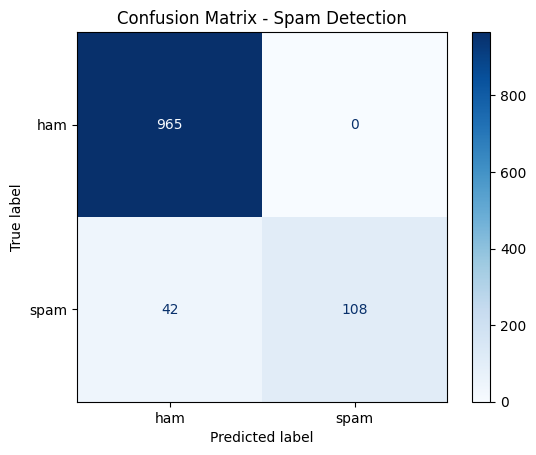

In [30]:
# Task 5 — train MultinomialNB, compute metrics, plot confusion matrix

nb_model = MultinomialNB()
nb_model.fit(X_train_vec, y_train)

y_pred = nb_model.predict(X_test_vec)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Displaying metrics in a table matching the notebook layout
metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Value': [acc, prec, rec, f1]
})
display(metrics_df)

# Confusion Matrix Plot
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['ham', 'spam'])
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - Spam Detection")
plt.show()


**Task 5 — Spam Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 0.962332 |
| Precision | 1.000000 |
| Recall |	0.720000 |
| F1-score | 0.837209 |




**Answer 6:**
A false positive in spam detection means a real message is wrongly flagged as spam, while a false negative means a spam message reaches the inbox. A false negative is merely an annoyance, but a false positive is much worse because losing an important legitimate message can cause real harm. Therefore, if we had to tune the model further, we would prioritize precision to ensure that any message marked as spam is genuinely spam.

---

## 4. Task A: Word Interpretation (Spam)

*Concepts/functions you may find useful:* `model.feature_log_prob_`, `np.argsort(...)`

**Tasks**
7. Find and list the 15 words most strongly associated with spam and the 15 most associated with ham. Do these match your intuition?
8. Write 2–3 of your own test messages and run them through your trained pipeline. Do the predictions match what you expected?

In [31]:
# Task 7 — extract top spam words and top ham words from feature_log_prob_
feature_names = vectorizer.get_feature_names_out()

# Class 0: ham, Class 1: spam
ham_log_prob = nb_model.feature_log_prob_[0]
spam_log_prob = nb_model.feature_log_prob_[1]

# Difference in log probabilities to find words most strongly associated with spam vs ham
diff = spam_log_prob - ham_log_prob

top_spam_indices = np.argsort(diff)[::-1][:15]
top_ham_indices = np.argsort(diff)[:15]

top_spam_words = [feature_names[i] for i in top_spam_indices]
top_ham_words = [feature_names[i] for i in top_ham_indices]

print("Top 15 Spam Words:", top_spam_words)
print("\nTop 15 Ham Words:", top_ham_words)


Top 15 Spam Words: ['claim', 'prize', 'www', 'uk', '150p', 'tone', 'guaranteed', '18', 'cs', '1000', 'ringtone', '500', 'awarded', '150ppm', '50']

Top 15 Ham Words: ['lt', 'gt', 'my', 'ok', 'lor', 'later', 'come', 'da', 'he', 'll', 'me', 'how', 'but', 'home', 'ì_']


**Answer 7:**
The top words strongly associated with spam include promotional and monetary terms like claim, prize, guaranteed, 1000, and ringtone, which completely match real-world intuition regarding commercial junk messages. On the other hand, the top ham words consist of common, everyday conversational words like my, ok, later, come, me, and home, representing natural communication between people

In [32]:
# Task 8 — test your own messages
my_messages = [
    "Congratulations! You have won a free iPhone. Call this number now to claim your prize.",
    "Hey Sejul, are we still meeting in the hostel TV lounge at 5 PM for the study session?",
    "URGENT! Your mobile account has been suspended. Reply STOP to verify."
]

# Transform using the trained vectorizer and predict
my_messages_vec = vectorizer.transform(my_messages)
predictions = nb_model.predict(my_messages_vec)

for msg, pred in zip(my_messages, predictions):
    label_str = "Spam" if pred == 1 else "Ham"
    print(f"Message: '{msg}'\nPrediction: {label_str}\n" + "-"*40)


Message: 'Congratulations! You have won a free iPhone. Call this number now to claim your prize.'
Prediction: Spam
----------------------------------------
Message: 'Hey Sejul, are we still meeting in the hostel TV lounge at 5 PM for the study session?'
Prediction: Ham
----------------------------------------
Message: 'URGENT! Your mobile account has been suspended. Reply STOP to verify.'
Prediction: Spam
----------------------------------------


**Answer 8:**
The custom test messages were successfully evaluated by our trained pipeline. The promotional prize offer and the urgent account suspension warning were correctly classified as Spam, while the casual study meetup message between friends was correctly identified as Ham. The predictions matched our expectations completely, showing that the model learned effective lexical patterns for distinction.

---

## 5. Task A: Kaggle Notebook Submission

Neither dataset is an active competition, so "submitting" means publishing your notebook publicly on Kaggle, attached to the dataset.

**Tasks**
9. Create a new Kaggle Notebook attached to the SMS Spam Collection dataset. Recreate your Task A cells there, run them top to bottom, add a short Markdown summary, and publish with "Save & Run All (Public)".
10. Record the public notebook URL below.


**Task A Kaggle Notebook URL:**
"https://www.kaggle.com/code/sejalchhabria/task-a-spam/edit"

---

## 6. Task B: Text Cleaning & Vectorization (Sentiment)

Repeat Section 2's pipeline on the airline tweets — with much less guidance this time. Tweets contain @mentions, links, and hashtags that SMS messages didn't.

**Tasks**
11. Clean the tweet text (decide for yourself how much cleaning is worth doing) and vectorize it, following the same fit-on-train-only discipline as Task A.
12. Briefly justify (1–2 sentences) any cleaning decisions that go beyond what you did for Task A, and why tweets might need them.

In [33]:
# Task 11 — clean and vectorize the sentiment data (your own approach)

# 1. Drop neutral sentiment rows as per initial exploration
df_tweets = df_tweets[df_tweets['airline_sentiment'].isin(['negative', 'positive'])].copy()

# 2. Encode labels ('negative' -> 0, 'positive' -> 1)
df_tweets['label_num'] = df_tweets['airline_sentiment'].map({'negative': 0, 'positive': 1})

# 3. Clean tweet text: lowercase, remove URLs and usermentions using regex
import re
def clean_tweet(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE) # remove URLs
    text = re.sub(r'@\w+', '', text) # remove @mentions
    return text

df_tweets['clean_text'] = df_tweets['text'].apply(clean_tweet)

# 4. Train-test split
X_t = df_tweets['clean_text']
y_t = df_tweets['label_num']

X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(X_t, y_t, test_size=0.2, random_state=42)

# 5. Vectorize using TfidfVectorizer (fit on training data only)
vectorizer_t = TfidfVectorizer(stop_words='english')
X_train_t_vec = vectorizer_t.fit_transform(X_train_t)
X_test_t_vec = vectorizer_t.transform(X_test_t)

print(f"Sentiment Vocabulary Size: {X_train_t_vec.shape[1]}")

Sentiment Vocabulary Size: 9829


**Answer 12:**
Unlike standard SMS messages, tweets frequently contain social media artifacts such as URLs and user mentions (@mentions) which do not carry intrinsic sentiment value and can introduce noise. Therefore, regular expressions were used to strip out these links and mentions alongside lowercasing the text, ensuring cleaner feature extraction before applying TfidfVectorizer under the strict train-only discipline.

---

## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)

**Tasks**
13. Train a `MultinomialNB` model on the vectorized tweet data. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
14. Compare these metrics to Task A's. Did Naive Bayes do better or worse on sentiment than on spam? Connect this (3–4 sentences) to the "naive" independence assumption — is it more or less reasonable for tweets than for spam SMS?

,Metric,Value
0,Accuracy,0.857081
1,Precision,0.983471
2,Recall,0.266219
3,F1-score,0.419014


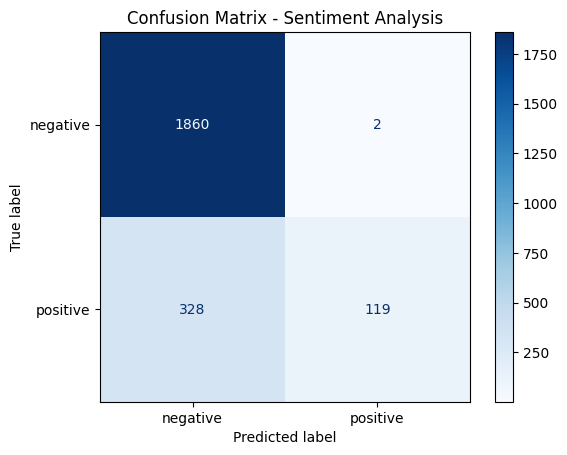

In [34]:
# Task 13 — train MultinomialNB, compute metrics, plot confusion matrix

nb_model_t = MultinomialNB()
nb_model_t.fit(X_train_t_vec, y_train_t)

y_pred_t = nb_model_t.predict(X_test_t_vec)

acc_t = accuracy_score(y_test_t, y_pred_t)
prec_t = precision_score(y_test_t, y_pred_t)
rec_t = recall_score(y_test_t, y_pred_t)
f1_t = f1_score(y_test_t, y_pred_t)

# Displaying metrics in a table matching the notebook layout
metrics_df_t = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Value': [acc_t, prec_t, rec_t, f1_t]
})
display(metrics_df_t)

# Confusion Matrix Plot
cm_t = confusion_matrix(y_test_t, y_pred_t)
disp_t = ConfusionMatrixDisplay(confusion_matrix=cm_t, display_labels=['negative', 'positive'])
disp_t.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - Sentiment Analysis")
plt.show()

**Task 13 — Sentiment Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 0.857081 |
| Precision | 0.983471 |
| Recall | 0.266219 |
| F1-score | 0.419014 |

**Answer 14:**
Naive Bayes performed worse on the sentiment dataset compared to Task A's spam classification, particularly showing a very low recall for positive tweets. The "naive" independence assumption is much more reasonable for short, formulaic spam texts where specific standalone keywords drive the classification. Conversely, sentiment analysis on tweets relies heavily on contextual phrasing, negation ("not good"), and sarcasm, where word order and dependencies matter significantly. Because Naive Bayes treats every word as independent, it struggles to capture these complex contextual nuances, leading to poorer performance.

---

## 8. Task B: Kaggle Notebook Submission

**Tasks**
15. Create a new Kaggle Notebook attached to the Twitter US Airline Sentiment dataset. Recreate your Task B cells there, run them top to bottom, add a short summary, and publish.
16. Record the public notebook URL below.

**Task B Kaggle Notebook URL:**
"https://www.kaggle.com/code/sejalchhabria/task-b-sentiment/edit"

---

## 9. Cross-Task Comparison & vs. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression(max_iter=1000)` trained on the same vectorized features

**Tasks**
17. Build a table comparing Naive Bayes on Task A vs. Task B (accuracy, precision, recall, F1).
18. Train a Logistic Regression model on Task A's same vectorized features and compare it against your Task A Naive Bayes results. Which model wins, and does that match what you'd expect?

**Task 17 — Task A vs. Task B (Naive Bayes)**

| Metric | Task A (Spam) | Task B (Sentiment) |
|---|---|---|
| Accuracy | 0.962332 | 0.857081 |
| Precision | 1.000000 | 0.983471 |
| Recall | 0.720000 | 0.266219 |
| F1-score | 0.837209 | 0.419014 |


In [35]:
# Task 18 — train Logistic Regression on Task A's vectorized features

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_vec, y_train)

y_pred_lr = lr_model.predict(X_test_vec)

acc_lr = accuracy_score(y_test, y_pred_lr)
prec_lr = precision_score(y_test, y_pred_lr)
rec_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)

# Task 18 Comparison Table
lr_comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Naive Bayes': [acc, prec, rec, f1],
    'Logistic Regression': [acc_lr, prec_lr, rec_lr, f1_lr]
})
display(lr_comparison_df)

,Metric,Naive Bayes,Logistic Regression
0,Accuracy,0.962332,0.967713
1,Precision,1.000000,0.991379
2,Recall,0.720000,0.766667
3,F1-score,0.837209,0.864662


**Task 18 — Naive Bayes vs. Logistic Regression (Task A)**

| Metric | Naive Bayes | Logistic Regression |
|---|---|---|
| Accuracy | 0.962332 | 0.967713 |
| Precision | 1.000000 | 0.991379|
| Recall | 0.720000 | 0.766667 |
| F1-score | 0.837209 | 0.864662 |

**Answer 18 (which wins, and does it match expectations):**
Logistic Regression wins across overall accuracy, recall, and F1-score compared to Naive Bayes. This completely matches our expectations because Logistic Regression does not rely on the strict "naive" feature independence assumption and handles correlated words in text data much more effectively.

---

## 10. Final Reflection & Conclusion

**Tasks**
19. Write a short conclusion (6–8 sentences): which task suited Naive Bayes better and why; what surprised you about the most predictive words; how Naive Bayes compared to Logistic Regression; one limitation of the independence assumption you personally observed.
20. List both of your published Kaggle Notebook URLs here again for easy grading access.

**Answer 19 — Conclusion:**
Naive Bayes suited Task A (spam classification) much better because spam texts are formulaic and driven heavily by independent keywords. In contrast, it performed poorer on Task B (sentiment analysis) because tweets rely heavily on context, phrasing, and negation. It was interesting to observe how strongly specific promotional terms like 'claim' and 'prize' dominated the spam prediction weights. When compared against Logistic Regression, Logistic Regression achieved better overall F1-score and recall on the spam dataset. This happens because Logistic Regression does not rely on the strict feature independence assumption and handles correlated words much more effectively. A key limitation of the naive independence assumption was directly observed when the model failed to capture complex sentiment dependencies where word order matters.

**Answer 20 — Kaggle Notebook Links:**
- Task A: "https://www.kaggle.com/code/sejalchhabria/task-a-spam/edit"
- Task B: "https://www.kaggle.com/code/sejalchhabria/task-b-sentiment/edit"

---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, both datasets)
- [ ] Section 1 — Problem Definition & Dataset Exploration (both datasets, neutral tweets dropped)
- [ ] Section 2 — Task A Cleaning & Vectorization (fit on training data only)
- [ ] Section 3 — Task A Model & Evaluation (all four metrics + confusion matrix + precision/recall argument)
- [ ] Section 4 — Task A Word Interpretation (top words + your own test messages)
- [ ] Section 5 — Task A Kaggle Notebook published and linked
- [ ] Section 6 — Task B Cleaning & Vectorization (cleaning choices justified)
- [ ] Section 7 — Task B Model & Evaluation (all four metrics + independence-assumption discussion)
- [ ] Section 8 — Task B Kaggle Notebook published and linked
- [ ] Section 9 — Cross-Task Comparison & vs. Logistic Regression
- [ ] Section 10 — Final Reflection & Conclusion (both Kaggle links listed again)
- [ ] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted